# 02｜黑马头条数据管理平台项目实战

> 本篇以“黑马头条”后台管理场景为主线，把 AJAX、Axios、Vue 响应式数据、登录鉴权、列表查询、分页、表单编辑和错误处理串成一个可复用的前端工程。重点不是记住某个页面，而是掌握“页面状态 ↔ 接口请求 ↔ 服务端响应”的完整闭环。

## 学习目标

- 能从需求拆出页面、状态、接口和权限边界。
- 能创建统一 Axios 实例，集中处理 baseURL、超时、Token、错误提示。
- 能实现登录、文章列表筛选分页、编辑发布、删除和退出登录。
- 能正确处理 loading、空数据、失败、重复提交和过期 Token。
- 能用浏览器 Network 面板核对请求方法、参数、请求头、状态码和响应结构。

## 1. 项目定位：管理端的四条主链路

黑马头条管理端通常包含四条链路：

1. **身份链路**：登录获取 Token，后续请求携带 Token，退出时清理本地凭证。
2. **内容链路**：文章分类、文章列表、新增、编辑、发布、删除。
3. **状态链路**：搜索条件、分页、表单草稿、加载状态、错误提示都属于页面状态。
4. **权限链路**：未登录跳转登录页，接口返回 401 时清理 Token 并重新登录。

前端不应该把业务数据写死在模板里，而是由响应式状态承接接口响应，再让 Vue 负责渲染。接口地址、字段名和响应包装以实际项目文档为准，下面的 `/api` 路径是便于跟练的占位约定。

## 2. 推荐目录与职责

```text
src/
├─ api/
│  ├─ http.js          # Axios 实例、拦截器
│  ├─ auth.js          # 登录、退出、用户信息
│  └─ article.js       # 文章与分类接口
├─ router/
│  └─ index.js         # 路由与登录守卫
├─ views/
│  ├─ Login.vue
│  ├─ ArticleList.vue
│  └─ ArticleEdit.vue
├─ components/         # 可复用表单、分页、空状态
└─ utils/
   ├─ storage.js
   └─ format.js
```

组件只负责展示和触发事件，接口调用集中在 `api/`，Token 的读写集中在 `utils/`。这样切换后端地址或更换错误提示时，不需要逐个页面修改。

## 3. 先约定接口契约

| 场景 | 方法 | 路径示例 | 请求数据 | 成功结果 | 常见失败 |
|---|---|---|---|---|---|
| 登录 | POST | `/api/auth/login` | `{ username, password }` | `{ token, user }` | 401 |
| 当前用户 | GET | `/api/auth/me` | 无 | `{ id, username, role }` | 401 |
| 文章列表 | GET | `/api/articles` | `params` 中的筛选与分页 | `{ rows, total }` | 400 |
| 文章详情 | GET | `/api/articles/:id` | 路径参数 | 文章对象 | 404 |
| 新增/编辑 | POST/PUT | `/api/articles` | JSON 请求体 | 保存后的文章 | 400/422 |
| 删除 | DELETE | `/api/articles/:id` | 路径参数 | `{ success: true }` | 404/409 |

先确认接口的字段类型。例如分页可能叫 `page/pageSize`，也可能叫 `pageNo/pageSize`；总数可能在 `total`，也可能在 `data.total`。前端代码必须以 Network 面板中真实响应为准。

In [ ]:
// api/http.js
import axios from 'axios'

export const http = axios.create({
  baseURL: '/api',
  timeout: 10000,
  headers: { 'Content-Type': 'application/json' }
})

http.interceptors.request.use((config) => {
  const token = localStorage.getItem('token')
  if (token) config.headers.Authorization = `Bearer ${token}`
  return config
})

http.interceptors.response.use(
  (response) => response,
  (error) => {
    if (error.response?.status === 401) {
      localStorage.removeItem('token')
      // 在真实项目中用路由跳转到 /login，并携带 redirect
    }
    return Promise.reject(error)
  }
)

### 为什么要统一封装 Axios？

- 每个页面不用重复写 `baseURL`、超时和 Token。
- 401、网络断开、服务端 500 可以统一记录和提示。
- 以后增加刷新 Token、请求取消、全局 loading 时只改一个地方。
- 组件中的代码更接近业务：`articleApi.list(params)`，而不是到处拼接 URL。

In [ ]:
// api/auth.js
import { http } from './http'

export const authApi = {
  async login(payload) {
    const { data } = await http.post('/auth/login', payload)
    localStorage.setItem('token', data.token)
    return data.user
  },
  async me() {
    const { data } = await http.get('/auth/me')
    return data
  },
  logout() {
    localStorage.removeItem('token')
  }
}

// api/article.js
export const articleApi = {
  list(params) { return http.get('/articles', { params }) },
  detail(id) { return http.get(`/articles/${id}`) },
  create(payload) { return http.post('/articles', payload) },
  update(id, payload) { return http.put(`/articles/${id}`, payload) },
  remove(id) { return http.delete(`/articles/${id}`) }
}

## 4. 登录页：提交、保存凭证与跳转

登录页至少要有 `form`、`loading`、`error` 三类状态。提交时先阻止浏览器默认跳转，校验必填项，再发请求；请求成功后保存 Token 并跳转，失败时保留输入内容。不要把密码写入 URL、日志或 localStorage。

In [ ]:
// Login.vue 的核心逻辑（选项式写法）
export default {
  data() {
    return {
      form: { username: '', password: '' },
      loading: false,
      error: ''
    }
  },
  methods: {
    async submit() {
      if (!this.form.username || !this.form.password) {
        this.error = '请输入用户名和密码'; return
      }
      this.loading = true
      this.error = ''
      try {
        await authApi.login(this.form)
        this.$router.replace(this.$route.query.redirect || '/')
      } catch (err) {
        const status = err.response?.status
        this.error = status === 401 ? '用户名或密码错误' : '登录失败，请稍后重试'
      } finally {
        this.loading = false
      }
    }
  }
}

## 5. 文章列表：筛选与分页必须是一份状态

列表页的请求参数通常由 `keyword`、`categoryId`、`status`、`page`、`pageSize` 组成。点击搜索时把页码重置为 1；切换页码时沿用当前筛选条件；清空时恢复默认对象。GET 参数放在 Axios 的 `params` 中，避免手工拼接导致中文、空格和 `&` 编码错误。

In [ ]:
// ArticleList.vue 的核心状态与查询
export default {
  data() {
    return {
      query: { keyword: '', categoryId: '', status: '', page: 1, pageSize: 10 },
      rows: [],
      total: 0,
      loading: false,
      error: ''
    }
  },
  computed: {
    totalPages() { return Math.max(1, Math.ceil(this.total / this.query.pageSize)) }
  },
  methods: {
    async loadArticles() {
      this.loading = true; this.error = ''
      try {
        const { data } = await articleApi.list({ ...this.query })
        this.rows = Array.isArray(data.rows) ? data.rows : []
        this.total = Number(data.total) || 0
      } catch (err) {
        this.rows = []; this.total = 0
        this.error = '文章列表加载失败，请检查网络或稍后重试'
      } finally { this.loading = false }
    },
    search() { this.query.page = 1; this.loadArticles() },
    clear() {
      this.query = { keyword: '', categoryId: '', status: '', page: 1, pageSize: 10 }
      this.loadArticles()
    },
    changePage(page) {
      if (page < 1 || page > this.totalPages || this.loading) return
      this.query.page = page; this.loadArticles()
    }
  },
  mounted() { this.loadArticles() }
}

### 列表模板的关键点

- `v-for="row in rows"` 必须给稳定的 `:key="row.id"`，不要用数组下标。
- 加载中显示 loading；加载完成且 `rows.length === 0` 时显示空状态；请求失败显示错误状态。
- 删除成功后，如果当前页只剩一条记录，应把页码调整到合法范围后重新查询。
- 搜索按钮在请求期间禁用，避免旧响应覆盖新响应。需要更复杂的搜索时，再引入请求取消或递增 requestId。

## 6. 文章编辑与发布：表单是一个可校验的状态机

编辑页要区分三种状态：

1. `draft`：用户正在填写的草稿。
2. `loading`：详情加载或保存请求进行中。
3. `submitting`：保存按钮已提交，必须避免重复点击。

进入编辑页先根据路由参数读取详情；新增页使用默认草稿。保存前做前端校验，保存成功后回到列表；失败时保留草稿和错误提示。

In [ ]:
const emptyDraft = () => ({
  title: '', categoryId: '', content: '', cover: '', status: 'draft'
})

export default {
  data() {
    return { id: this.$route.params.id || null, draft: emptyDraft(), loading: false, submitting: false, error: '' }
  },
  async mounted() {
    if (!this.id) return
    this.loading = true
    try { this.draft = (await articleApi.detail(this.id)).data }
    catch { this.error = '文章详情加载失败' }
    finally { this.loading = false }
  },
  methods: {
    validate() {
      if (!this.draft.title.trim()) return '请输入标题'
      if (!this.draft.categoryId) return '请选择分类'
      if (!this.draft.content.trim()) return '请输入正文'
      return ''
    },
    async save() {
      const message = this.validate()
      if (message || this.submitting) { this.error = message; return }
      this.submitting = true; this.error = ''
      try {
        const payload = { ...this.draft, title: this.draft.title.trim() }
        if (this.id) await articleApi.update(this.id, payload)
        else await articleApi.create(payload)
        this.$router.push('/articles')
      } catch (err) {
        this.error = err.response?.status === 422 ? '表单数据不符合要求' : '保存失败，请稍后重试'
      } finally { this.submitting = false }
    }
  }
}

## 7. 删除、发布与可逆操作

删除是不可逆风险更高的操作，页面应先确认，再发起 `DELETE`。发布可以视作状态更新，接口成功后刷新当前行或列表。不要只在前端把行删掉就认为后端删除成功：网络失败时，前端状态和服务端已经不一致。

```js
async remove(row) {
  if (!window.confirm(`确定删除“${row.title}”吗？`)) return
  this.loading = true
  try {
    await articleApi.remove(row.id)
    await this.loadArticles()
  } catch {
    this.error = '删除失败，文章仍然保留'
  } finally {
    this.loading = false
  }
}
```

如果产品要求撤回或放入回收站，应优先设计成可恢复的状态变更，而不是直接删除。

## 8. 路由守卫与过期 Token

路由守卫负责在进入管理页面前检查 Token；它不能代替后端鉴权。即使前端放行，服务端仍必须验证 Token 和用户权限。

```js
router.beforeEach((to) => {
  const hasToken = Boolean(localStorage.getItem('token'))
  if (to.meta.requiresAuth && !hasToken) {
    return { path: '/login', query: { redirect: to.fullPath } }
  }
  if (to.path === '/login' && hasToken) return '/'
})
```

请求返回 401 时清除 Token，跳转登录页；不要把 401 当成普通空列表，否则用户会误以为没有数据。

## 9. Vue 生命周期与请求时机

- `mounted` 适合页面首次显示后拉取文章列表或详情。
- 搜索、分页、保存等请求由用户事件触发，不要无条件放进 `updated`，否则容易形成请求循环。
- 组件销毁时清理定时器、事件监听和可取消的请求。
- 异步请求完成后组件可能已经离开页面，复杂页面应检查当前组件是否仍然有效，或使用 AbortController 取消请求。

## 10. Network 面板排错顺序

1. **Request URL**：路径、baseURL 和环境是否正确。
2. **Request Method**：GET 参数是否放在 `params`，POST 数据是否放在请求体。
3. **Request Headers**：是否带有 `Authorization: Bearer ...`。
4. **Payload / Query String**：字段名、类型、分页参数是否符合接口约定。
5. **Status Code**：400 看参数，401 看登录，403 看权限，404 看路径，409 看业务冲突，422 看校验，500 看服务端。
6. **Response**：确认数组到底位于 `data.rows`、`data.data` 还是其他位置。

如果响应正文是 HTML，通常意味着请求打到了错误页面或代理，而不是业务接口；不要直接对 HTML 响应使用 `response.data.rows`。

## 11. 一个可运行的最小列表页面

下面的片段用于验证“查询 → loading → 响应 → 渲染”链路。把接口地址替换成课程提供的实际地址，并根据真实响应调整 `rows/total` 的取值。

In [ ]:
<div id="app" v-cloak>
  <form @submit.prevent="search">
    <input v-model.trim="query.keyword" placeholder="搜索标题" />
    <button :disabled="loading">{{ loading ? '查询中…' : '查询' }}</button>
  </form>
  <p v-if="error" role="alert">{{ error }}</p>
  <p v-else-if="loading">正在加载……</p>
  <p v-else-if="rows.length === 0">暂无文章</p>
  <ul v-else>
    <li v-for="article in rows" :key="article.id">
      <strong>{{ article.title }}</strong>
      <span>{{ article.status }}</span>
    </li>
  </ul>
</div>

<script type="module">
import { createApp } from 'vue'
import axios from 'axios'
const http = axios.create({ baseURL: '/api', timeout: 10000 })
createApp({
  data: () => ({ query: { keyword: '', page: 1, pageSize: 10 }, rows: [], loading: false, error: '' }),
  methods: {
    async search() {
      this.loading = true; this.error = ''
      try {
        const { data } = await http.get('/articles', { params: this.query })
        this.rows = Array.isArray(data.rows) ? data.rows : []
      } catch { this.rows = []; this.error = '请求失败，请检查接口和网络' }
      finally { this.loading = false }
    }
  },
  mounted() { this.search() }
}).mount('#app')
</script>

## 12. AJAX 与 Axios 基础回顾

### 6.1 概述

我们前端页面中的数据，如下图所示的表格中的员工信息，应该来自于后台，那么我们的后台和前端是互不影响的2个程序，那么我们前端应该如何从后台获取数据呢？因为是2个程序，所以必须涉及到2个程序的交互，所以这就需要用到我们接下来学习的Ajax技术。

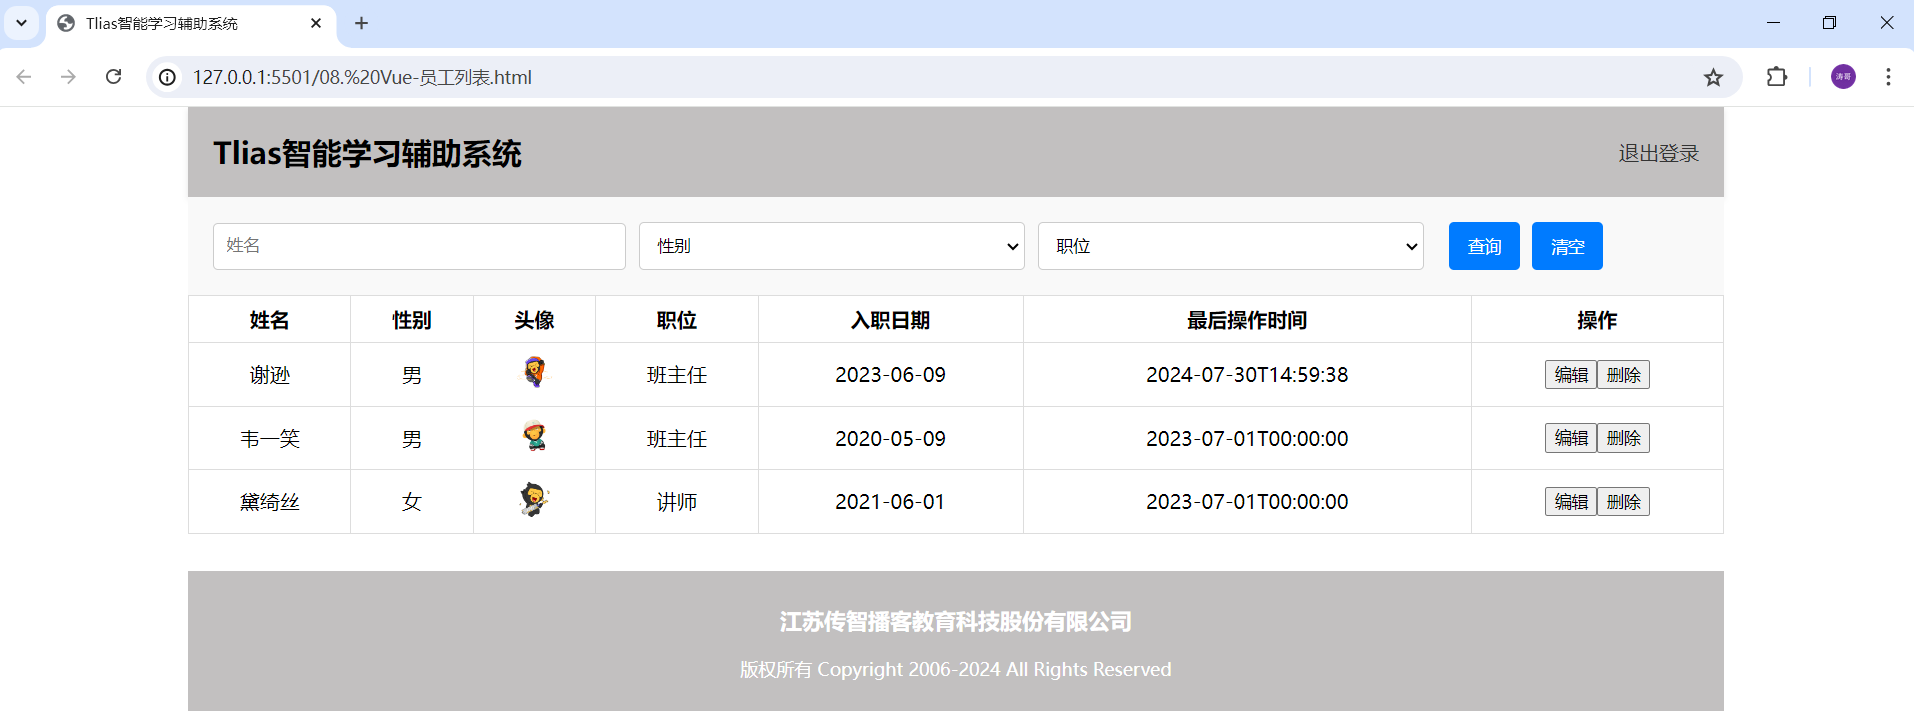

<strong>Ajax:</strong> 全称Asynchronous JavaScript And XML，异步的JavaScript和XML。其作用有如下2点：

- 与服务器进行数据交换：通过Ajax可以给服务器发送请求，并获取服务器响应的数据。
- 异步交互：可以在<strong>不重新加载整个页面</strong>的情况下，与服务器交换数据并<strong>更新部分网页</strong>的技术，如：搜索联想、用户名是否可用的校验等等。

我们详细的解释一下Ajax技术的2个作用：

- 与服务器进行数据交互

如下图所示前端资源被浏览器解析，但是前端页面上缺少数据，前端可以通过Ajax技术，向后台服务器发起请求，后台服务器接受到前端的请求，从数据库中获取前端需要的资源，然后响应给前端，前端在通过我们学习的vue技术，可以将数据展示到页面上，这样用户就能看到完整的页面了。此处可以对比JavaSE中的网络编程技术来理解。

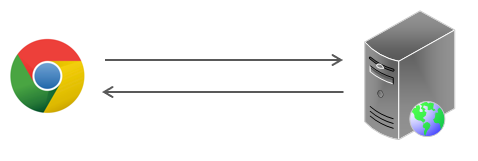

- 异步交互：可以在<strong>不重新加载整个页面</strong>的情况下，与服务器交换数据并<strong>更新部分网页</strong>的技术。

如下图所示，当我们再百度搜索java时，下面的联想数据是通过Ajax请求从后台服务器得到的，在整个过程中，我们的Ajax请求不会导致整个百度页面的重新加载，并且只针对搜索栏这局部模块的数据进行了数据的更新，不会对整个页面的其他地方进行数据的更新，这样就大大提升了页面的加载速度，用户体验高。

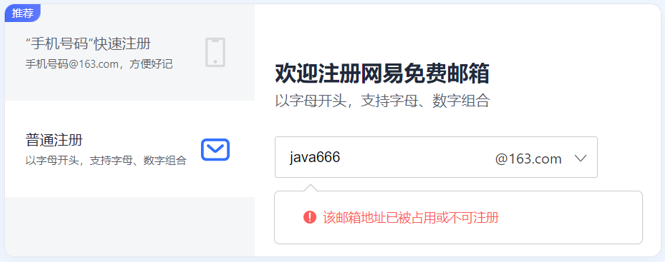

> XML：（英语：E<strong>x</strong>tensible <strong>M</strong>arkup <strong>L</strong>anguage）可扩展标记语言，本质是一种数据格式，可以用来存储复杂的数据结构。
> 
> > **补充：**Ajax 名称保留了 XML，但现代接口经常返回 JSON。本章 Axios 返回 JSON 数据后交给 Vue 渲染，不要求使用 XML。


### 6.2 同步异步

针对于上述Ajax的局部刷新功能是因为Ajax请求是异步的，与之对应的有同步请求。接下来我们介绍一下异步请求和同步请求的区别。

> **补充：**“不整页跳转”与“异步等待”要分开理解：脚本拿到响应后主动修改数据或 DOM，才形成局部更新；异步使等待网络结果时页面仍可处理其他任务。这里的同步示意针对阻塞主线程的等待，不应理解为所有普通 HTTP 访问都会冻结浏览器。

- <strong>同步请求</strong>发送过程如下图所示：

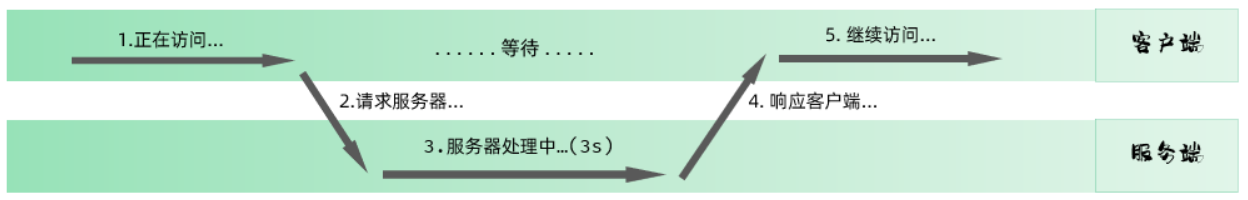

浏览器页面在发送请求给服务器，在服务器处理请求的过程中，浏览器页面不能做其他的操作。只能等到服务器响应结束后才能，浏览器页面才能继续做其他的操 作。 

- <strong>异步请求</strong>发送过程如下图所示：

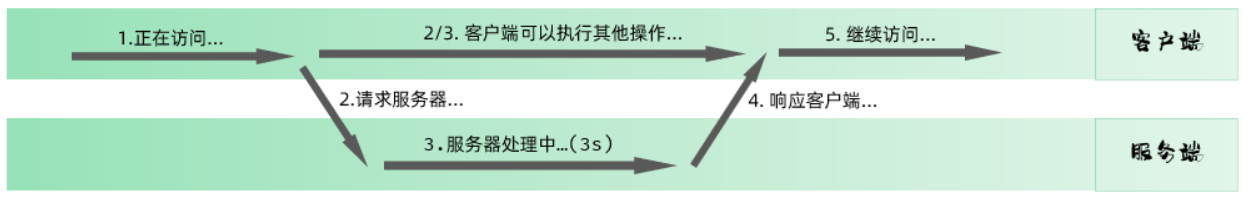

 浏览器页面发送请求给服务器，在服务器处理请求的过程中，浏览器页面还可以做其他的操作。


### 6.3 Axios

使用原生的Ajax请求的代码编写起来还是比较繁琐的，所以接下来我们学习一门更加简单的发送Ajax请求的技术Axios 。Axios是对原生的AJAX进行封装，简化书写。Axios官网是：<code>https://www.axios-http.cn</code>

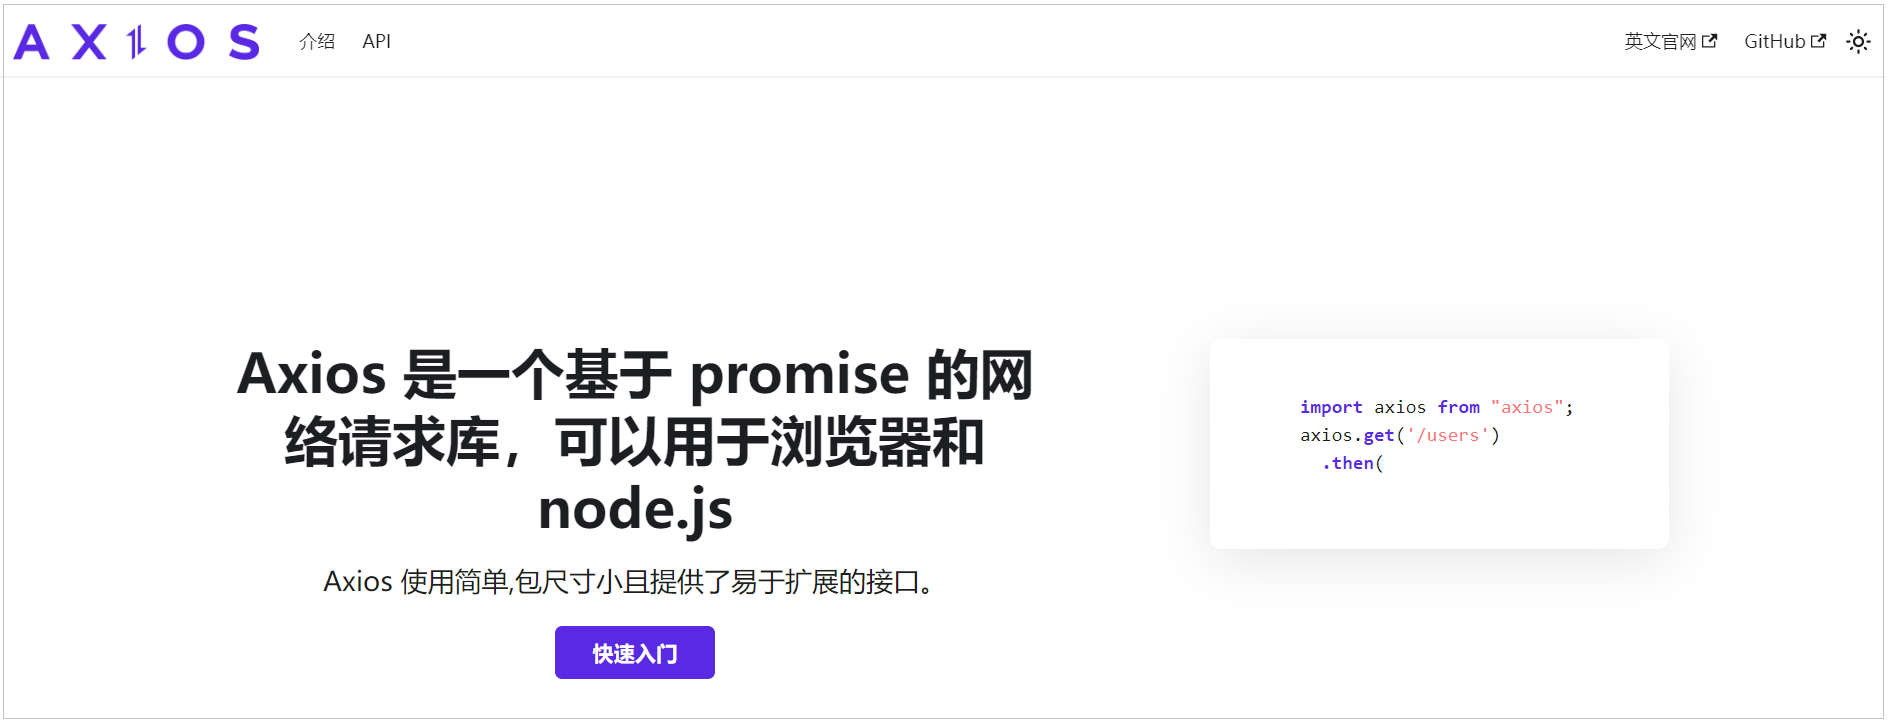


#### 6.3.1 入门程序

Axios的使用比较简单，主要分为2步：

1). 引入Axios文件（如果网络不通畅，可以使用离线的已经下载好的js文件，资料中已经提供）

````html
<script src="https://unpkg.com/axios/dist/axios.min.js"></script>
````

2). 点击按钮时，使用Axios发送请求

````html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Axios入门程序</title>
</head>
<body>

  <button id="getData">GET</button>
  <button id="postData">POST</button>
  
  <script src="https://unpkg.com/axios/dist/axios.min.js"></script>
  <script>
    //GET请求
    document.querySelector('#getData').onclick = function() {
      axios({
        url:'https://mock.apifox.cn/m1/3083103-0-default/emps/list',
        method:'get'
      }).then(function(res) {
        console.log(res.data);
      }).catch(function(err) {
        console.log(err);
      })
    }
    
    //POST请求
    document.querySelector('#postData').onclick = function() {
      axios({
        url:'https://mock.apifox.cn/m1/3083103-0-default/emps/update',
        method:'post'
      }).then(function(res) {
        console.log(res.data);
      }).catch(function(err) {
        console.log(err);
      })
    }
  </script>
</body>
</html>
````

> 知识小贴士：在使用axios时，在axios之后，输入 thenc 会自动生成成功及失败回调函数结构 。
> 
> > **补充：**`thenc` 属于编辑器或扩展提供的代码片段提示，不是 JavaScript 或 Axios 的关键字。没有该提示时，手工写 `.then(...).catch(...)` 即可。


#### 6.3.2 请求方法别名

Axios还针对不同的请求，提供了别名方式的api，具体格式如下：

axios.请求方式(url &#91;, data &#91;, config&#93;&#93;)

具体如下：

| 方法 | 描述 |
| --- | --- |
| axios.get(url &#91;, config&#93;) | 发送get请求 |
| axios.delete(url &#91;, config&#93;) | 发送delete请求 |
| axios.post(url &#91;, data&#91;, config&#93;&#93;) | 发送post请求 |
| axios.put(url &#91;, data&#91;, config&#93;&#93;) | 发送put请求 |

> **补充：**GET 的第二个参数是配置对象：`axios.get(url, { params: { name: '谢逊' } })`；POST 的第二个参数是请求体数据，第三个才是配置：`axios.post(url, { id: 1 }, config)`。不能把 POST 的参数顺序直接套给 GET。用 `params` 可以自动编码中文、空格和 `&` 等字符，比手工拼查询串更稳妥。

我们目前只关注get和post请求，所以在上述的入门案例中，我们可以将get请求代码改写成如下：

````javascript
axios.get("https://mock.apifox.cn/m1/3083103-0-default/emps/list").then(result => {
    console.log(result.data);
})
````

post请求改写成如下：

````javascript
axios.post("https://mock.apifox.cn/m1/3083103-0-default/emps/update","id=1").then(result => {
    console.log(result.data);
})
````

> **补充：**`"id=1"` 是字符串形式的请求体，不等同于 `{ id: 1 }` 这个对象。发送 JSON 对象还是表单编码，应以接口约定为准；服务端处理的名称、类型与 `Content-Type` 要对应。练习中的公共 POST 地址只用于课程演示，不要拿真实业务接口做随意修改测试。


### 7.1 介绍

vue的生命周期：指的是vue对象从创建到销毁的过程。

vue的生命周期包含8个阶段：每触发一个生命周期事件，会自动执行一个生命周期方法，这些生命周期方法也被称为钩子方法。其完整的生命周期如下图所示：

| 状态 | 阶段周期 |
| --- | --- |
| beforeCreate | 创建前 |
| created | 创建后 |
| beforeMount | 挂载前 |
| mounted | 挂载完成 |
| beforeUpdate | 更新前 |
| updated | 更新后 |
| beforeDestroy | 销毁前 |
| destroyed | 销毁后 |

> **勘误：**原表最后两项 `beforeDestroy / destroyed` 是 Vue 2 名称。本章使用 Vue 3，应对应 `beforeUnmount / unmounted`。下方讲义生命周期图展示的已经是 Vue 3 名称。

| Vue 3 选项式钩子 | 什么时候执行 | 本章应如何理解 |
| --- | --- | --- |
| `beforeCreate` | 组件状态初始化前 | 此时不要依赖尚未初始化的 `data`、`methods` |
| `created` | 组件状态初始化后 | 可访问数据和方法，DOM 尚未挂载 |
| `beforeMount` | 初次挂载前 | 即将把初次渲染结果放入页面 |
| `mounted` | 初次挂载完成 | 本章在这里发起员工列表查询 |
| `beforeUpdate` | 响应式状态引起 DOM 更新前 | 数据已经变化，DOM 尚未完成本次更新 |
| `updated` | DOM 更新完成后 | 不要在此无条件改数据并反复触发更新 |
| `beforeUnmount` | 卸载前 | 可以开始清理副作用 |
| `unmounted` | 卸载完成后 | 确认定时器、手工监听等已清理 |

> **补充：**这八项是本章介绍的主要钩子，并非 Vue 所有生命周期 API 的完整清单。`mounted` 不表示图片、异步组件和网络数据都已经加载完毕；其中的异步请求完成后，还会引起一次界面更新。

下图是 Vue 官网提供的从创建 Vue 到效果 Vue 对象的整个过程及各个阶段对应的钩子函数：

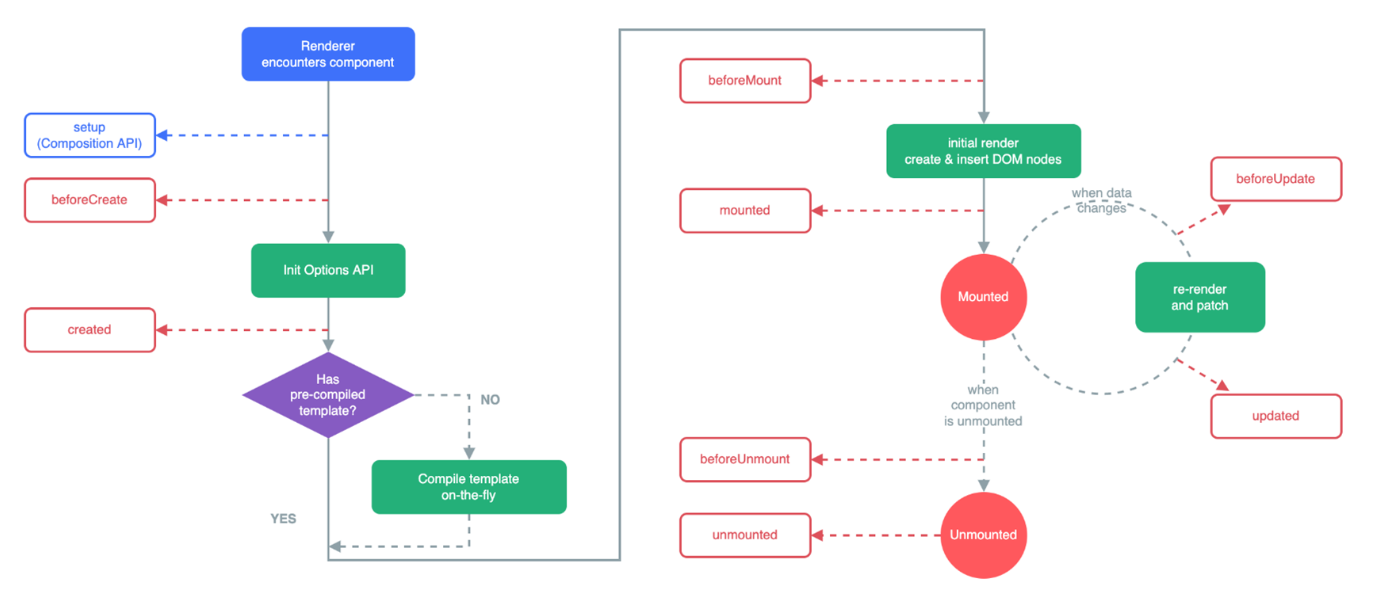

其中我们需要重点关注的是mounted，其他的我们了解即可。

mounted：挂载完成，Vue初始化成功，HTML页面渲染成功。<strong>以后我们一般用于页面初始化自动的ajax请求后台数据</strong>


### 7.2 案例完善

那我们要想在页面加载完毕，就查询出员工列表，就可以在mounted钩子函数中，发送异步请求查询员工数据了。 

具体代码如下：

````javascript
    methods: {
      async search() {
        //基于axios发送异步请求，请求https://web-server.itheima.net/emps/list，根据条件查询员工列表
        const result = await axios.get(`https://web-server.itheima.net/emps/list?name=${this.searchForm.name}&gender=${this.searchForm.gender}&job=${this.searchForm.job}`);
        this.empList = result.data.data;
      },
      clear() {
        this.searchForm= {
          name: '',
          gender: '',
          job: ''
        }
        this.search();
      }
    },
    mounted() {
      this.search();
    }
  }).mount('#container')
````

> **代码位置说明：**这一段是 Vue 选项对象中的方法片段，要放在 `methods: { ... }` 内，并保留同级 `data()` 与挂载代码；它不是可以直接粘贴为独立 JS 文件的完整程序。调用 `async` 方法会得到 Promise，`await` 后面的赋值要等请求成功后才执行，失败应由 `try/catch` 或调用方捕获。

到此，员工列表查询的功能我们就已经完成了。 那关于Vue的其他高级用法，我们将在后面的前端web实战中来详细讲解。


## 8 附录

- <strong>Ajax练习的url地址：</strong>

    - Ajax演示：

        - GET请求:  https://mock.apifox.cn/m1/3083103-0-default/emps/list
        - POST请求: https://mock.apifox.cn/m1/3083103-0-default/emps/update
    - Ajax员工列表案例地址： 

        - https://web-server.itheima.net/emps/list
        - https://web-server.itheima.net/emps/list?name=xxx&amp;gender=xxx&amp;job=xxx

- <strong>Chrome浏览器插件地址：</strong>https://chrome.zzzmh.cn/&#35;/index

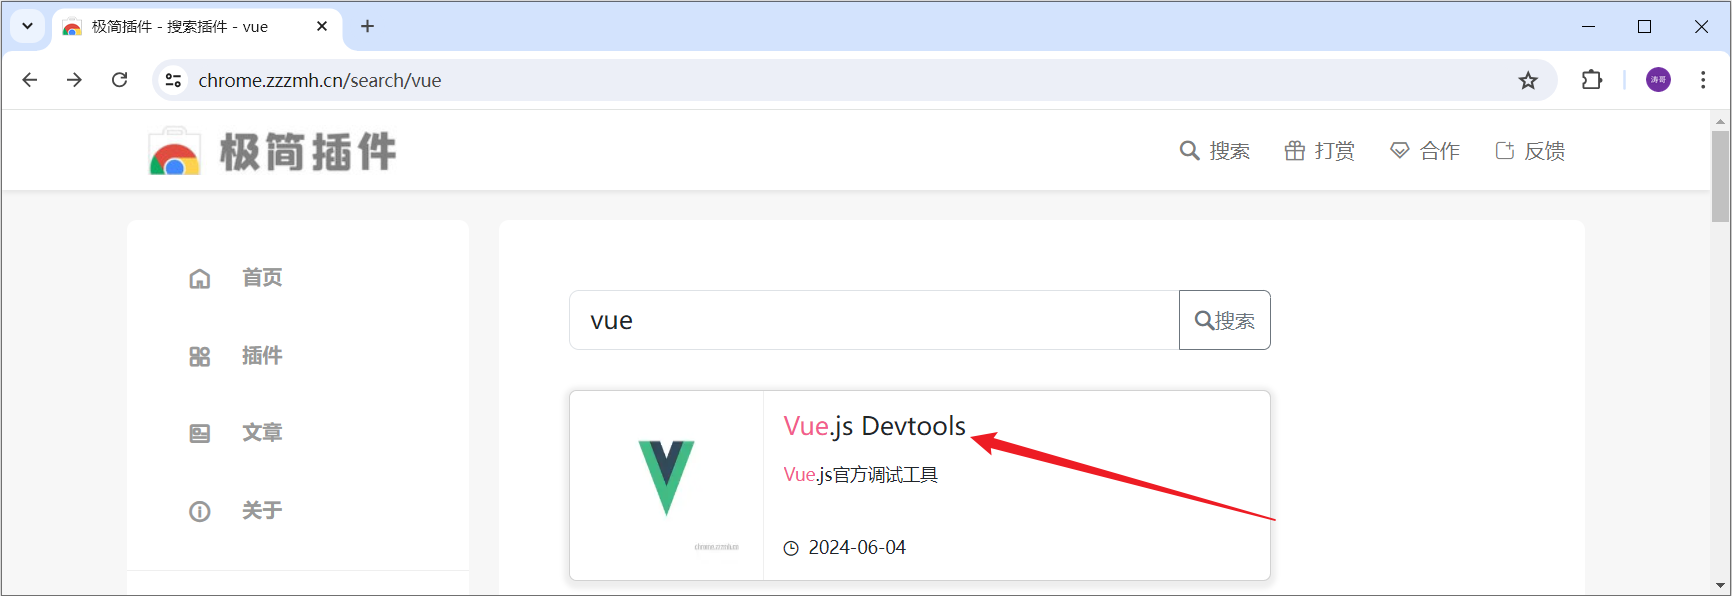


### 8.1 补充：运行时按现象排查

| 现象 | 优先检查 |
| --- | --- |
| 对象例子报 `user.eat is not a function` | 讲义笔误；对象定义的是 `sing`，调用改为 `user.sing()` |
| 第一个标题无法修改 | 元素是否已加载、选择器是否匹配、返回值是否为 `null` 或空列表 |
| 页面显示 `{{message}}` | Vue 模块加载、`type="module"`、挂载区域及控制台错误 |
| 图片替代文字出现 `{{ emp.name }}` | 改成 `:alt="emp.name"`，HTML 属性不使用文本插值语法 |
| 职位为空或性别显示不对 | 核对接口返回的是字符串还是数字，与比较表达式保持一致 |
| 点击查询整页跳转 | 使用 `@submit.prevent` 或明确设置 `type="button"`，阻止不需要的原生提交 |
| 清空后表单数据不一致 | 修改 `searchForm`，不要只依赖原生 reset；需要重载列表时调用 `search()` |
| `await` 报语法错误 | 放在 `async` 函数或支持顶层 await 的模块中；讲义方法片段要放回 `methods` |
| 请求返回 405、404 或 HTML | 查看状态和响应正文，区分接口拦截、地址失效与数据结构问题；可切换本地练习 |
| 控制台显示 CORS 错误 | 由服务端配置允许的来源，或使用开发代理；单纯在页面里改几个请求头不能替服务器授权 |
| 初次进入没有员工 | 检查 `mounted()` 与 `methods` 是否同级、是否调用 `this.search()`、请求是否成功 |

讲义末尾的浏览器插件页面是第三方分发入口，截图属于课程当时版本。查看 Vue 组件数据时，按 Vue 官方文档选择与 Vue 3 匹配的 Devtools；不用插件也可以在浏览器自带的控制台、元素和网络面板里完成本章的大部分检查。


## 13. 项目复习清单

- [ ] 能画出登录、列表、编辑、删除四条请求链路。
- [ ] 能解释 Axios 实例、请求拦截器和响应拦截器的职责。
- [ ] 能写出带筛选、分页和 Token 的列表请求。
- [ ] 能区分 `params`、请求体和路径参数。
- [ ] 能处理 loading、空状态、错误状态和重复提交。
- [ ] 能根据 401、403、404、422、500 定位问题。
- [ ] 能在保存成功后刷新或返回列表，失败时保留用户输入。
- [ ] 能说明前端路由守卫不能替代后端权限校验。

### 建议实战顺序

1. 先用本地 JSON 完成文章列表展示。
2. 再接入 GET 列表接口，加入筛选与分页。
3. 加登录和 Axios Token 拦截器。
4. 完成新增、编辑和删除，并补充请求失败提示。
5. 最后加入路由守卫、权限按钮和请求取消。